[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/priyapalhandique/gci-company-a-bill-certainty/blob/main/PriyapalDSAI.ipynb)

**Run it end to end:** Runtime → Run all. The notebook downloads its SHA-256-verified data and code bundle on the first code cell; no Drive mount or local setup is required.

# Final Assignment Tutorial — Telecom

This notebook is a reference walkthrough for the GCI World 2026 Winter final assignment.
The dataset comes from **Company A**, an anonymous telecommunications service provider, and contains historical customer information across two linked tables (`Client.csv`, `Record.csv`).

Your task is to analyze this data, build a machine learning model whose output supports a concrete business proposal — not to build the best possible model.

**What this notebook walks through:**
1. Market context.
2. Loading and merging the two source tables.
3. EDA: shape, missingness, target distribution, and a worked feature example.
4. Problem Definition — choosing the target and the ML task.
5. Preprocessing — what EDA told us we have to do.
6. A baseline churn classifier.
7. Model evaluation and feature importance.
8. From model to business proposal.

> **Treat this as a reference, not a template.** The strongest submissions diverge from it: a different target, a different segment, a different lever. Originality is rewarded.


> **Build note — GCI World 2026 final assignment**
> Student account: `PriyapalDSAI`.
> This notebook is a copy of the course tutorial. Sections 1–9 and their order are preserved; the added cells are marked "Added" and contain the client-specific analysis for Company A.
> **Portable build:** the same notebook runs on Google Colab or locally. It resolves a workspace that contains the data and source modules; if that workspace is absent, it downloads a pinned, SHA-256-verified bundle. Every data file is checked against the recorded SHA-256 manifest before modelling. No machine-specific paths are used.

---

## 1.Introduction & Market Analysis


### 1.1 Company context
*Company A* is a wireless telecommunications operator. They have years of usage and billing data on roughly 100,000 customers but no in-house machine learning capability.

When a company commissions a business proposal, they usually arrive with a vague sense that *something* needs to improve — margins, retention, growth, customer satisfaction — but no clear view of which lever to pull, which segment to focus on, or even which question to start with. **Choosing the question is the analyst's first job, and the rest of the proposal stands or falls on it.** The dataset rarely points to a single obvious answer; it admits several, and which one you pursue determines the kind of recommendation you can make.

This dataset includes a binary `churn` flag — whether a customer left within 31–60 days after the observation date — and we use churn as the worked example throughout this notebook. But churn is one of many viable targets the data supports. **You may and should explore other targets** — revenue, usage, equipment lifecycle, segment-level behaviour. Pick the question whose answer best supports the proposal you want to make.

### 1.2 Why this market matters
- Acquiring a new subscriber costs several times more than keeping one — retention, usage, and ARPU all translate directly into margin.
- Mature, saturated markets grow by taking customers from competitors or lifting revenue per existing customer.
- Behaviour signals (usage decline, complaints, equipment ageing) precede both churn and revenue compression by months.

**Questions to think about:**
- What does the telecom market look like in your country or region — who are the major players, what local dynamics (regulation, technology shifts, new entrants) are reshaping churn, and what story can you tell about a specific market you know? A proposal grounded in a local market you can describe concretely is more compelling than one assembled from generic global figures.
- What recent, citable sources can you find that quantify these claims for your target market? Uncited industry numbers will not strengthen your case.
- What share of churn in this market is voluntary (customer-initiated) versus involuntary (non-payment, address change)? Which one can a model meaningfully address?

---

## 2.Setup and Data Loading


### 2.1 Import libraries and portable setup

The tutorial imports its libraries here. This build adds a portable bootstrap so the notebook runs unchanged on Google Colab or on a local machine:

- On Colab the workspace is `/content/gci_work`; on a local run it is the folder that contains `data/` and `src/`.
- If the workspace is missing, the notebook downloads a pinned release bundle and verifies its SHA-256 before extracting it.
- `xgboost` and `lightgbm` are installed only if they are missing.
- All paths then come from `src/config.py`, which resolves relative to the workspace — never from the machine's current directory.

In [1]:
# =============================================================================
# Portable setup — runs unchanged on Google Colab and on a local machine.
# No machine-specific paths. The workspace is either the folder that contains
# this notebook (local build) or /content/gci_work (Colab), materialised from
# a pinned, SHA-256-verified bundle when it is not already present.
# =============================================================================
import hashlib
import importlib.util
import os
import subprocess
import sys
import tempfile
import urllib.request
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

BUNDLE_URL = (
    "https://github.com/priyapalhandique/gci-company-a-bill-certainty/"
    "releases/download/v2/gci_company_a_bundle_v2.zip"
)
BUNDLE_SHA256 = "64397993e675e1e14e5d492d91e7481520d08e98497d1a93debe2d393b50cb14"


def _sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _is_workspace(path: Path) -> bool:
    return (
        (path / "data" / "Client.csv").is_file()
        and (path / "data" / "Record.csv").is_file()
        and (path / "src" / "guardrails.py").is_file()
        and (path / "source_hashes.json").is_file()
    )


def _find_local_workspace() -> Path | None:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if _is_workspace(candidate):
            return candidate
    return None


def _install_missing(packages: list[tuple[str, str]]) -> None:
    for import_name, pip_name in packages:
        if importlib.util.find_spec(import_name) is None:
            print(f"Installing {pip_name} ...")
            subprocess.run(
                [sys.executable, "-m", "pip", "install", "-q", pip_name],
                check=True,
            )


def _download_bundle(destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    archive = Path(tempfile.gettempdir()) / "gci_company_a_bundle.zip"
    try:
        print("Downloading pinned reproducibility bundle ...")
        urllib.request.urlretrieve(BUNDLE_URL, archive)
    except Exception as exc:
        print("Automatic download failed:", exc)
        try:
            from google.colab import files

            print("Upload gci_company_a_bundle.zip to continue.")
            uploaded = files.upload()
            if not uploaded:
                raise RuntimeError("No bundle uploaded")
            archive = Path(next(iter(uploaded)))
        except Exception as upload_exc:
            raise RuntimeError(
                "Could not obtain the workspace bundle. Download it manually from "
                f"{BUNDLE_URL} and place it at {archive}."
            ) from upload_exc

    digest = _sha256_file(archive)
    if digest != BUNDLE_SHA256:
        raise RuntimeError(
            "Bundle SHA-256 mismatch: "
            f"expected {BUNDLE_SHA256}, got {digest}. Refusing to run."
        )
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(destination)
    if not _is_workspace(destination):
        raise RuntimeError(f"Bundle did not contain the expected workspace: {destination}")


_install_missing([("xgboost", "xgboost"), ("lightgbm", "lightgbm")])

if IN_COLAB:
    WORK = Path("/content/gci_work")
else:
    WORK = _find_local_workspace() or (Path.cwd() / "_gci_bundle")

if not _is_workspace(WORK):
    _download_bundle(WORK)

sys.path.insert(0, str(WORK / "src"))
import config as cfg  # noqa: E402

WORK = cfg.WORK
DATA_DIR = cfg.DATA
FIG_DIR = cfg.FIGURES
OUT_DIR = cfg.OUTPUT
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import seaborn as sns  # noqa: E402

from sklearn.preprocessing import LabelEncoder  # noqa: E402
from sklearn.model_selection import train_test_split  # noqa: E402
from sklearn.metrics import accuracy_score, confusion_matrix  # noqa: E402

from xgboost import XGBClassifier, plot_importance  # noqa: E402

pd.set_option("display.max_columns", 120)

import guardrails  # noqa: E402

guardrails.set_seeds(42)
guardrails.verify_sources()

print(f"Colab runtime: {IN_COLAB}")
print(f"Workspace: {WORK.name}")
print("Guardrail bootstrap: PASS")

Colab runtime: False
Workspace: _gci_bundle
Guardrail bootstrap: PASS


### 2.2 Workspace and data source

The course tutorial mounts Google Drive at this point and asks you to `cd` into the folder that holds the dataset. **This submission does not depend on Drive or on any local machine.**

The setup cell already resolved a portable workspace and verified the data:

- **On Colab:** `/content/gci_work`, downloaded from the pinned release bundle on first run.
- **Locally:** the `work/` folder that contains this notebook, or a downloaded fallback bundle if the data are absent.

The next cell reports the resolved paths and file sizes.

In [2]:
# The tutorial mounts Google Drive here. This build does not need Drive:
# the setup cell above already resolved and verified a portable workspace.
print("Workspace:", WORK.name)
print("Data directory:", DATA_DIR.name)
for name in ("Client.csv", "Record.csv"):
    path = DATA_DIR / name
    print(f"{name}: {path.stat().st_size:,} bytes")

Workspace: _gci_bundle
Data directory: data
Client.csv: 17,937,775 bytes
Record.csv: 30,182,432 bytes


### 2.3 Load the two source tables

The dataset is split across two files:

| File | Granularity | Contents |
|---|---|---|
| `Client.csv` | one row per customer | account-level info: tenure, plan, demographics, equipment |
| `Record.csv` | one row per customer | mean monthly usage, billing, and call-quality metrics, plus the `churn` target |

Both tables share a `Customer_ID` column, which we use to join them into a single analysis table.


In [3]:
client_path = DATA_DIR / "Client.csv"
record_path = DATA_DIR / "Record.csv"

for path in (client_path, record_path):
    print(f"{'OK ' if path.exists() else 'MISSING '} {path.name}")
    assert path.exists(), f"Missing required file: {path.name}"

OK  Client.csv
OK  Record.csv


In [4]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client: {client.shape}")
print(f"Record: {record.shape}")

assert client.shape == (100_000, 50), client.shape
assert record.shape == (100_000, 51), record.shape
assert client["Customer_ID"].is_unique
assert record["Customer_ID"].is_unique
print("Shape / key assertions: PASS")


Client: (100000, 50)
Record: (100000, 51)
Shape / key assertions: PASS


In [5]:
# Merge on Customer_ID. Both tables have one row per customer, so this is a 1:1 join.
df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print(f"Merged: {df.shape}")
assert df.shape == (100_000, 100), df.shape
checks = guardrails.assert_dataset(df)
print("Dataset checks:", checks)
print("Churners:", int(df["churn"].sum()), f"({df['churn'].mean():.2%})")
df.head()


Merged: (100000, 100)
Dataset checks: {'rows': True, 'unique_customers': True, 'churn_binary': True, 'churn_count': 49562}
Churners: 49562 (49.56%)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


---

## 3.Exploratory Data Analysis

Before modeling, three questions need answers:

1. **How big and structured is the data?** Rows, columns, dtypes.
2. **Where is the data incomplete or unreliable?**
3. **What does the target variable look like?**

Each answer constrains the next step. The shape and types tell us what preprocessing is required. The missingness tells us which columns may need to be dropped, imputed, or treated specially. The target distribution tells us which metrics will be meaningful.

EDA is also where the proposal starts to take shape — the patterns you see now become candidate signals for the model and anchors for the story your proposal will tell. The visualizations in this tutorial are intentionally minimal — just enough to make a point; for your proposal slides, you will want to polish them.

### 3.1 Shape and types

`df.info(verbose=False)` reports total rows, total columns, the count of columns of each dtype, and memory use. Two things to read from the output:

- **Dataset size.** Small enough to keep in pandas — no chunking needed.
- **Dtype mix.** Some columns may be stored as `object` (text). Most machine learning models can only learn from numbers, so any text columns will need to be converted to numeric form before modeling.

In [6]:
df.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), str(21)
memory usage: 76.3 MB


### 3.2 Missing values

A column that is mostly missing carries little signal — dropping it is often cleaner than trying to impute. We count the missing values in each column, take the 20 worst, and plot them.

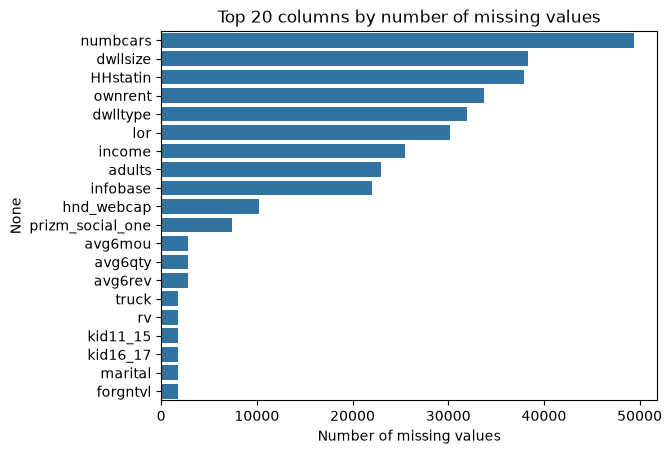

In [7]:
# Count of missing values per column
missing_counts = df.isna().sum()

# Take the 20 columns with the most missing values
top_missing = missing_counts.sort_values(ascending=False).head(20)

# Plot
sns.barplot(x=top_missing.values, y=top_missing.index)
plt.xlabel('Number of missing values')
plt.title('Top 20 columns by number of missing values')
plt.show()

### 3.3 Target variable: churn

We'll use `churn` as the worked example. Before modeling we need its class balance — whether stayers and churners appear in roughly equal numbers, or whether one class dominates. The balance directly affects which evaluation metric will be meaningful: accuracy is informative only when classes are balanced; with 5% churn it would be misleading.

churn
0    50438
1    49562
Name: count, dtype: int64

churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64


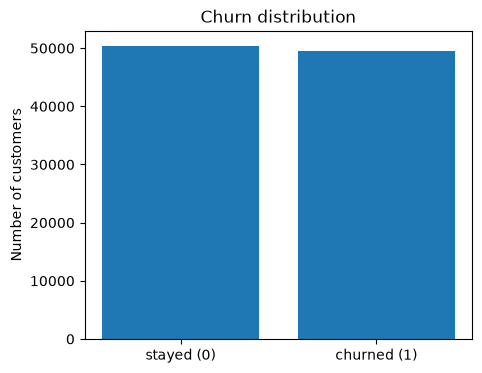

In [8]:
# Counts and proportions
print(df['churn'].value_counts())
print()
print(df['churn'].value_counts(normalize=True))

# Bar chart
counts = df['churn'].value_counts().sort_index()
labels = ['stayed (0)', 'churned (1)']

plt.figure(figsize=(5, 4))
plt.bar(labels, counts.values)
plt.title('Churn distribution')
plt.ylabel('Number of customers')
plt.show()

Churn is near 50% — unusually balanced for telecom (real-world datasets are typically 5–10% churn). For this dataset, accuracy will be a meaningful metric, and a model that always predicts one class will score around 0.5. If you choose a different target, redo this balance check before picking your evaluation metric.

### 3.4 A closer look: equipment age vs churn

The three checks above are dataset-wide. The real EDA work is digging into individual features — how each one relates to the target, where the differences are, and which patterns are worth following up on.

As one example: `eqpdays` records the age (in days) of each customer's current handset. Old equipment plausibly drives churn — a frustrating or outdated device makes the next contract renewal less attractive. We can check this by comparing the equipment-age distribution for churners against stayers.

Mean equipment age (stayed):  363.3 days
Mean equipment age (churned): 421.1 days


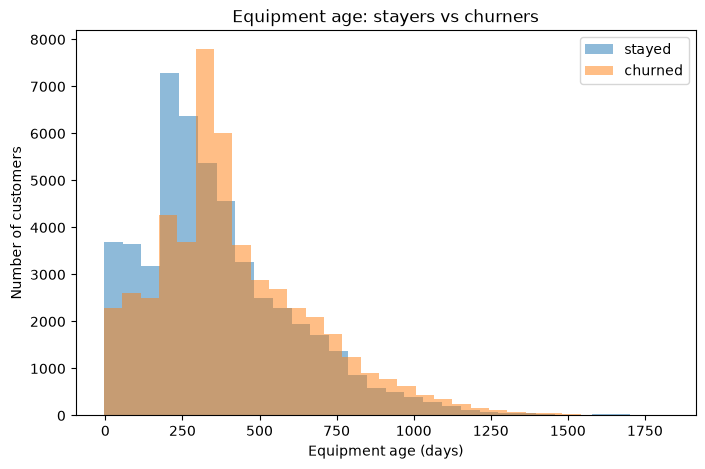

In [9]:
# Split eqpdays into two groups based on churn
stayed = df[df['churn'] == 0]['eqpdays']
churned = df[df['churn'] == 1]['eqpdays']

# Compare the averages
print(f'Mean equipment age (stayed):  {stayed.mean():.1f} days')
print(f'Mean equipment age (churned): {churned.mean():.1f} days')

# Overlay the two distributions
plt.figure(figsize=(8, 5))
plt.hist(stayed, bins=30, alpha=0.5, label='stayed')
plt.hist(churned, bins=30, alpha=0.5, label='churned')
plt.xlabel('Equipment age (days)')
plt.ylabel('Number of customers')
plt.title('Equipment age: stayers vs churners')
plt.legend()
plt.show()

Churners skew toward older equipment — the mean and the right tail of the distribution are both higher than for stayers. That makes `eqpdays` a candidate feature for both the model and the narrative your proposal will tell ("customers with ageing handsets are at higher risk; replacing or upgrading equipment is a lever").

The point is the **exercise**: pick a candidate feature, compare it across churn classes, and decide whether it is worth following up on. Repeat this on a handful of features that look promising from the dataset overview or your domain knowledge.

**Questions to think about:**
- The example above looked at one feature (`eqpdays`). Pick three or four other candidates — from the dataset overview, from Section 1.2, or from your own intuition — and run the same comparison.
- ~100 columns is a lot. Which look like near-duplicates of each other (e.g., several variations on revenue or minutes)?
- Are any columns *too good to be true* — could they leak the target?
- How does the target distribute across segments (geographic, plan, demographic, credit class)? Which segments behave differently and might deserve separate analysis?
- Are there outliers or implausible values you should clean before modeling?

### 3.5 Pairwise view: revenue, usage, equipment age, and churn

The previous plot looked at one feature at a time.  
Here we compare several business-relevant numeric features together:

- `rev_Mean`: average monthly revenue
- `mou_Mean`: average monthly minutes of use
- `totmrc_Mean`: average monthly recurring charge
- `eqpdays`: equipment age in days
- `months`: customer tenure

A pairplot helps us see whether churned customers occupy different regions in the joint feature space.

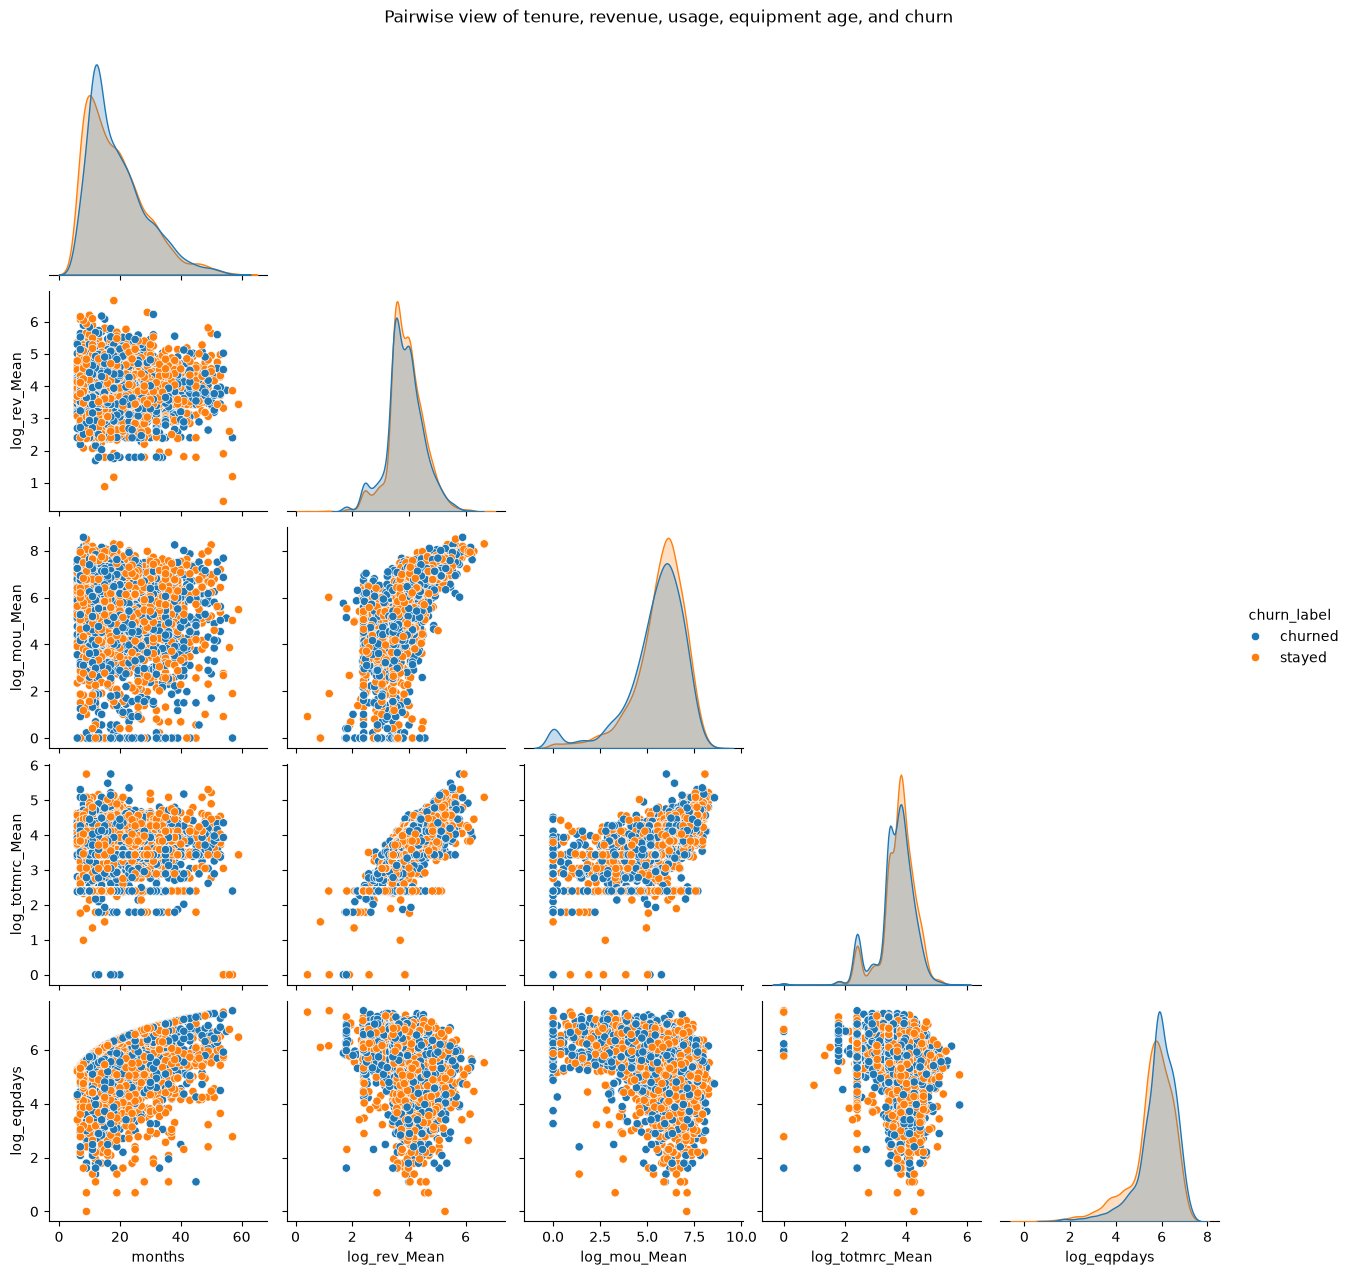

In [10]:
# Pairplot with log-transformed skewed variables
plot_df = df[[
    'months',
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'eqpdays',
    'churn'
]].dropna().copy()

# Log-transform highly skewed positive variables. A few billing rows are
# negative; mask them so log1p is defined and the plot drops them as before.
for col in ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'eqpdays']:
    plot_df[f'log_{col}'] = np.log1p(plot_df[col].where(plot_df[col] >= 0))

plot_df['churn_label'] = plot_df['churn'].map({
    0: 'stayed',
    1: 'churned'
})

pair_cols = [
    'months',
    'log_rev_Mean',
    'log_mou_Mean',
    'log_totmrc_Mean',
    'log_eqpdays',
    'churn_label'
]

pair_sample = plot_df[pair_cols].sample(n=5000, random_state=42)

sns.pairplot(
    pair_sample,
    hue='churn_label',
    corner=True,
    diag_kind='kde',
)

plt.suptitle('Pairwise view of tenure, revenue, usage, equipment age, and churn', y=1.02)
plt.show()

The pairplot does not show a clean geometric separation between churners and non-churners.
This suggests that churn is not explained by a single simple numeric variable such as revenue or usage alone.
However, the diagonal distributions indicate that equipment age (`eqpdays`) is somewhat shifted for churned customers, making it a more interpretable candidate for business intervention.
Revenue- and usage-related variables appear correlated with each other, so they may act as overlapping proxies rather than independent explanations.

### 3.6 Added — Revenue at risk: churn barely moves with value

Churn probability alone treats a $20/month customer and a $158/month customer as equally important. The business does not. We define **annual revenue at risk (RaR)** as:

`RaR = churn × monthly revenue × 12`

For EDA, we first use the *actual* outcome. Churn varies only modestly across revenue deciles (47.6%–54.1%), while average monthly revenue spans roughly 10× ($15 → $158). A probability-only model therefore spreads effort almost evenly across customers and under-weights the customers who hold most of the dollars.


,rev_decile,customers,churn_rate,avg_monthly_rev,annual_rev,annual_rar,rar_share,rev_share
0,1,10000,0.541,15.226,1827301.09,988434.36,0.029,0.026
1,2,10000,0.517,29.599,3551846.14,1830856.98,0.053,0.050
2,3,10000,0.503,33.301,3996091.39,2005920.74,0.058,0.057
3,4,10000,0.476,37.359,4483044.70,2133023.63,0.062,0.064
4,5,10000,0.479,43.902,5268211.91,2526915.08,0.073,0.075
5,6,10000,0.500,51.070,6128392.19,3061349.94,0.089,0.087
6,7,10000,0.484,58.334,7000123.68,3383920.53,0.098,0.099
7,8,10000,0.490,70.708,8484974.94,4156026.92,0.120,0.120
8,9,10000,0.477,89.452,10734277.99,5118679.01,0.148,0.152
9,10,10000,0.492,157.874,18944850.03,9386159.19,0.271,0.269


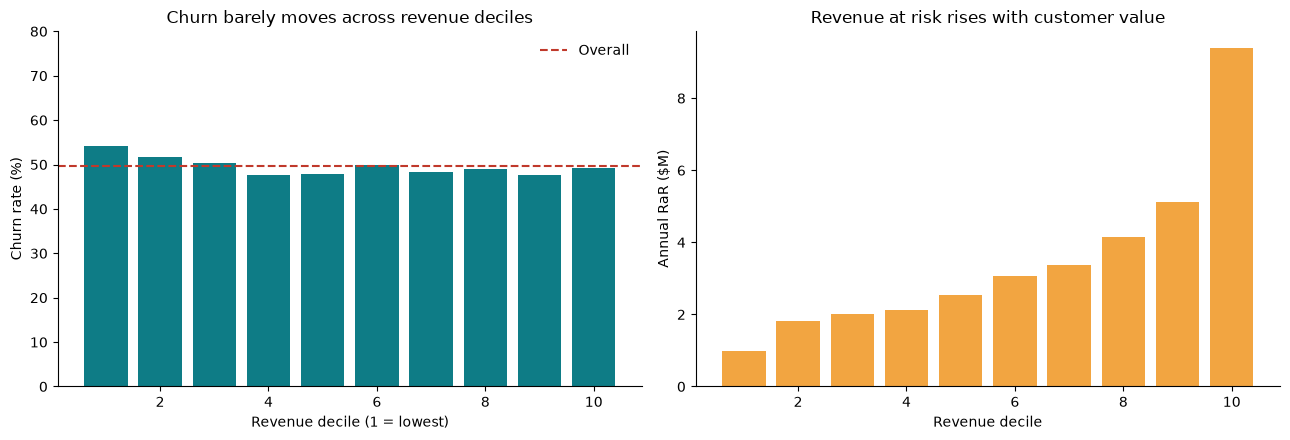

Total annual revenue $70.42M
Total annual revenue at risk $34.59M
Churn rate by revenue decile: 47.6%–54.1%


In [11]:
# Added: churn and revenue at risk by revenue decile
df["rev_imputed"] = df["rev_Mean"].fillna(df["rev_Mean"].median())
df["annual_rev"] = df["rev_imputed"].clip(lower=0) * 12
df["actual_rar"] = df["churn"] * df["annual_rev"]

df["rev_decile"] = pd.qcut(df["rev_imputed"].rank(method="first"), 10, labels=False) + 1
rev_profile = (
    df.groupby("rev_decile")
      .agg(customers=("churn", "size"),
           churn_rate=("churn", "mean"),
           avg_monthly_rev=("rev_imputed", "mean"),
           annual_rev=("annual_rev", "sum"),
           annual_rar=("actual_rar", "sum"))
      .reset_index()
)
rev_profile["rar_share"] = rev_profile["annual_rar"] / rev_profile["annual_rar"].sum()
rev_profile["rev_share"] = rev_profile["annual_rev"] / rev_profile["annual_rev"].sum()
display(rev_profile.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(rev_profile["rev_decile"], rev_profile["churn_rate"] * 100, color="#0E7C86")
axes[0].axhline(df["churn"].mean() * 100, color="#C0392B", ls="--", lw=1.5, label="Overall")
axes[0].set(title="Churn barely moves across revenue deciles", xlabel="Revenue decile (1 = lowest)", ylabel="Churn rate (%)")
axes[0].set_ylim(0, 80); axes[0].legend(frameon=False)

axes[1].bar(rev_profile["rev_decile"], rev_profile["annual_rar"] / 1e6, color="#F2A541")
axes[1].set(title="Revenue at risk rises with customer value", xlabel="Revenue decile", ylabel="Annual RaR ($M)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_churn_and_rar_by_revenue_decile.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Total annual revenue ${df['annual_rev'].sum()/1e6:.2f}M")
print(f"Total annual revenue at risk ${df['actual_rar'].sum()/1e6:.2f}M")
print(f"Churn rate by revenue decile: {rev_profile['churn_rate'].min():.1%}–{rev_profile['churn_rate'].max():.1%}")


### 3.7 Added — Profile of the high-value customer

Churn is nearly value-blind, so the customers who matter most are the high-value customers most likely to leave. We profile the top decile by **monthly revenue**. This is an EDA view, not the model's targeting list; the model uses only information available before the outcome.


In [12]:
# Added: top revenue-decile profile (EDA, not model output)
top = df[df["rev_decile"] == 10]

profile_cols = ["rev_imputed", "ovrrev_Mean", "totmrc_Mean", "mou_Mean", "eqpdays", "months", "custcare_Mean"]
profile = pd.DataFrame({
    "top_decile": top[profile_cols].fillna(0).mean(),
    "all_customers": df[profile_cols].fillna(0).mean(),
})
profile["multiple"] = profile["top_decile"] / profile["all_customers"]
display(profile.round(2))

overage_share = (top["ovrrev_Mean"].fillna(0).sum() / top["rev_imputed"].sum())
print(f"Top decile customers: {len(top):,}")
print(f"Churn: {top['churn'].mean():.1%}; avg monthly bill ${top['rev_imputed'].mean():.2f}")
print(f"Annual revenue: ${top['annual_rev'].sum()/1e6:.2f}M ({top['annual_rev'].sum()/df['annual_rev'].sum():.1%} of total)")
print(f"Annual revenue at risk: ${top['actual_rar'].sum()/1e6:.2f}M ({top['actual_rar'].sum()/df['actual_rar'].sum():.1%} of total)")
print(f"Overage: ${top['ovrrev_Mean'].fillna(0).mean():.2f}/month ({overage_share:.1%} of bill)")
print(f"Overage payers: {(top['ovrrev_Mean'].fillna(0) > 0).mean():.1%}")
print(f"Devices older than 12 months: {(top['eqpdays'] > 365).mean():.1%}")


,top_decile,all_customers,multiple
rev_imputed,157.87,58.68,2.69
ovrrev_Mean,70.74,13.51,5.24
totmrc_Mean,75.76,46.01,1.65
mou_Mean,1382.43,511.73,2.70
eqpdays,272.40,391.93,0.70
months,18.80,18.83,1.00
custcare_Mean,3.90,1.79,2.18


Top decile customers: 10,000
Churn: 49.2%; avg monthly bill $157.87
Annual revenue: $18.94M (26.9% of total)
Annual revenue at risk: $9.39M (27.1% of total)
Overage: $70.74/month (44.8% of bill)
Overage payers: 91.4%
Devices older than 12 months: 26.1%


### 3.8 Added — The bill-shock hypothesis

The top-decile profile is not a low-engagement story. It is high usage and high overage on a recurring charge that is only modestly above average. That points to a **plan-fit / bill-shock** hypothesis: customers on plans that do not match their usage see volatile bills and leave.

We test the gradient by splitting high-value customers into quintiles of overage share (overage revenue ÷ total revenue).


,overage_q,customers,churn_rate,avg_bill,avg_overage,avg_overage_share
0,1,5001,0.454,94.969,0.027,0.000
1,2,5000,0.443,103.464,11.471,0.110
2,3,5001,0.474,105.331,32.591,0.308
3,4,5000,0.499,115.184,54.965,0.476
4,5,5001,0.562,150.414,104.866,0.680


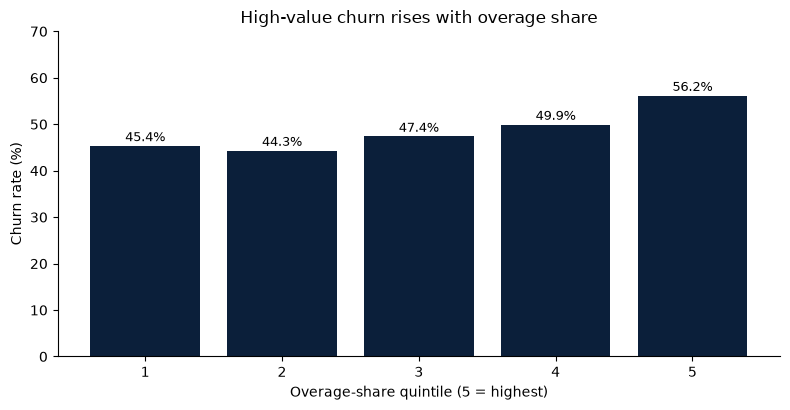

In [13]:
# Added: overage-share gradient among high-value customers
hv = df[df["rev_imputed"] >= df["rev_imputed"].quantile(0.75)].copy()
hv["overage_share"] = (hv["ovrrev_Mean"].fillna(0) / hv["rev_imputed"].replace(0, np.nan)).clip(0, 1)
hv["overage_q"] = pd.qcut(hv["overage_share"].rank(method="first"), 5, labels=False) + 1
overage_profile = (
    hv.groupby("overage_q")
      .agg(customers=("churn", "size"), churn_rate=("churn", "mean"),
           avg_bill=("rev_imputed", "mean"), avg_overage=("ovrrev_Mean", "mean"),
           avg_overage_share=("overage_share", "mean"))
      .reset_index()
)
display(overage_profile.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(overage_profile["overage_q"], overage_profile["churn_rate"] * 100, color="#0B1F3A")
ax.set(title="High-value churn rises with overage share", xlabel="Overage-share quintile (5 = highest)", ylabel="Churn rate (%)")
ax.set_ylim(0, 70)
ax.spines[["top", "right"]].set_visible(False)
for x, y in zip(overage_profile["overage_q"], overage_profile["churn_rate"] * 100):
    ax.text(x, y + 1, f"{y:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_high_value_churn_by_overage_share.png", dpi=200, bbox_inches="tight")
plt.show()


---

## 4.Problem Definition

The grading rubric scores your **business proposal**, not your model. The model is one input to the proposal — evidence that supports a specific recommendation. Before any preprocessing or modeling, write down — in a few sentences — what you are actually trying to solve, and what your proposal will ultimately recommend.

**Questions to think about:**
- Is `churn` really the right outcome for *your* proposal? Could revenue, usage, equipment turnover, or something segment-specific be a better fit? Justify your choice from what you saw in EDA.
- What ML task does your target imply — classification, regression, clustering, anomaly detection? Each implies different metrics and a different kind of recommendation.
- How would you state your business question in one sentence a non-technical executive would understand?
- Who acts on the model's output, and what action do they take? A model whose output cannot be acted on is not a proposal.
- What concrete recommendation do you expect your proposal to make? The modeling work in the rest of the notebook should serve that recommendation.

The rest of this notebook proceeds with `churn` as a worked example — but every section is replaceable.

### 4.1 Added — Problem definition for Company A

**Business objective.** Maximise retained contribution margin per retention dollar, not the number of saved customers.

**Core problem.** Retention spend is typically allocated by churn probability. In this dataset churn varies only 47.6%–54.1% across revenue deciles while average revenue spans 10×, so probability-only targeting sends offers to low-value customers and under-invests in the high-value customers who hold 27% of revenue at risk.

**ML task.** Binary classification: estimate each customer's probability of churn in the 31–60 day target window. Convert the probability into a decision score:

`expected annual revenue at risk = predicted churn probability × monthly revenue × 12`

**Primary metric.** ROC-AUC for ranking quality. **Business metrics.** Calibration (because probabilities are multiplied by dollars), top-decile lift, and share of annual revenue at risk captured in the targeted decile. **Guardrail metrics.** Fairness gaps by region and credit class, and stability across folds.

**Scope.** 100,000 accounts in the Company A sample; US wireless context. Sensitive demographic fields are excluded from the deployed model. Results are associative; the 90-day randomised pilot tests whether the proposed offer changes churn.

**Success criteria for the PoC.** AUC ≥ 0.69, calibration error ≤ 2 percentage points, top-decile RaR capture ≥ 25%, and a pilot churn reduction large enough to cover program cost (break-even to be computed in Section 8).


---

## 5.Preprocessing

EDA showed two things that need handling before we can train a model:

- Section 3.1 showed there are `object`-dtype columns. Most ML models can only learn from numbers, so these must be encoded.
- The data also includes `Customer_ID`, a unique identifier with no predictive value. Leaving it in lets the model "memorise" individuals and can destabilise feature importance.

The minimum we have to do is therefore: drop the ID, and convert each `object` column to integers. `LabelEncoder` maps each unique string to a distinct integer. It is the simplest possible encoder, and it makes two compromises worth knowing about:

- It imposes an arbitrary order on categories that have no natural one (e.g. `A=0, B=1, C=2` — the model sees `C` as "larger" than `A`).
- Casting to string first turns `NaN` into the literal string `"nan"`, so missing categorical values become just another category.

In [14]:
# Drop the ID and any column built from the target.
leaky = [c for c in ["Customer_ID", "actual_rar"] if c in df.columns]
df_clean = df.drop(columns=leaky)
print("Dropped:", leaky)

# Find text columns. pandas 3 uses a dedicated string dtype, so include both.
text_cols = [
    c for c in df_clean.columns
    if df_clean[c].dtype == object or pd.api.types.is_string_dtype(df_clean[c])
]
print("Columns to encode:", text_cols)

for col in text_cols:
    encoder = LabelEncoder()
    df_clean[col] = encoder.fit_transform(df_clean[col].astype(str))

assert "churn" in df_clean.columns
assert not any(c in df_clean.columns for c in ["Customer_ID", "actual_rar"])
print()
print("Shape after preprocessing:", df_clean.shape)
df_clean.head()


Dropped: ['Customer_ID', 'actual_rar']
Columns to encode: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']



Shape after preprocessing: (100000, 102)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,rev_imputed,annual_rev,rev_decile
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,2,1,1,0,0,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,2,13,3,0,149.98999,2.0,2.0,2,0.0,0.0,0,15.0,1,3,1.0,0,4.0,3.0,2,0,0.0,9,0,0,0,0,0,1,361.0,23.9975,287.97,1
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1,1,0,21,0,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,4,3,0,0,NaN,7.0,6.0,1,1.0,1.0,2,1.0,1,3,1.0,0,5.0,1.0,2,0,0.0,16,0,0,0,0,0,1,240.0,57.4925,689.91,7
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1,1,2,7,0,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,2,6,0,0,29.98999,2.0,1.0,3,0.0,0.0,0,7.0,1,2,2.0,0,5.0,2.0,2,0,0.0,9,0,1,0,0,0,1,1504.0,16.9900,203.88,1
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1,1,2,4,0,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,3,3,0,0,29.98999,1.0,1.0,3,0.0,0.0,2,6.0,0,2,4.0,0,6.0,1.0,2,3,0.0,14,1,0,0,0,0,1,1812.0,38.0000,456.00,4
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1,1,2,0,0,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,4,10,3,0,149.98999,6.0,4.0,2,0.0,0.0,1,5.0,0,3,1.0,0,6.0,1.0,2,14,0.0,6,0,0,0,0,0,1,434.0,55.2300,662.76,7


**Questions to think about:**
- How would you encode the categorical columns to preserve their information (e.g. keep `NaN` as its own category, or use a model that handles categoricals natively)?
- Beyond `Customer_ID`, are there columns you should drop — heavily missing (Section 3.2), near-duplicate, or likely to leak the target?
- What derived features — ratios, deltas, aggregates — could capture signal that no single raw column does (e.g. equipment-age relative to tenure, change in usage relative to baseline)?

---

## 6.Model Building (XGBoost)

The model is a tool the proposal uses, not the proposal itself. Its job is to give your recommendation an evidence base — *which signals matter, by how much, and for whom*. A great model with no actionable recommendation is not a passing submission. The goal of this section is not to maximise accuracy; it is to produce evidence the proposal can stand on.

A few choices in the code below are worth stating explicitly:

- **Why XGBoost.** The data is tabular with mixed numeric scales and label-encoded categoricals. XGBoost handles all of that without scaling, trains quickly on ~100K rows, gives feature importances we can use to explain the model, and has a simple sklearn-style API (`.fit()`, `.predict()`). It is one option among many — logistic regression (for interpretability), random forest, or LightGBM would also be reasonable.
- **Why a stratified train/test split.** We train on one slice and evaluate on a held-out slice the model hasn't seen. Stratifying by `churn` keeps both classes proportionally represented in both slices — useful at 50/50, essential if the target were imbalanced.
- **Why `random_state=42`.** Reproducibility — the grading rubric expects your notebook to give the same numbers when rerun.

In [15]:
# Features (X) and target (y)
X = df_clean.drop('churn', axis=1)
y = df_clean['churn']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Define the model
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    eval_metric='logloss',
    random_state=42,
)

# Train
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

### 6.1 Added — Five-fold comparison and model choice

The tutorial trains one XGBoost model on a single 70/30 split. The proposal needs a model choice that is stable and defensible, so we compare four candidates on identical stratified folds: logistic regression (interpretable baseline), XGBoost with all features, and LightGBM with all features and with the **fair feature set** (demographic and credit fields removed).

The deployed model is selected on out-of-fold ROC-AUC, calibration, and dollar-weighted capture — not accuracy. The comparison is implemented in `src/phase2_models.py` and is called below so the notebook regenerates every metric and figure.


In [16]:
import phase2_models as p2

p2.main()
%matplotlib inline
comparison = pd.read_csv(OUT_DIR / "model_comparison.csv")
display(comparison.round(3))

Fair features: 98 (12 categorical)
Full features: 108 (21 categorical)
Training Logistic ...


  Logistic fold 1/5: AUC 0.6364 (2.4s)


  Logistic fold 2/5: AUC 0.6375 (4.9s)


  Logistic fold 3/5: AUC 0.6318 (7.3s)


  Logistic fold 4/5: AUC 0.6358 (9.4s)


  Logistic fold 5/5: AUC 0.6380 (11.8s)
Training XGBoost (full) ...


... (14 outputs left out)

  LightGBM (fair) fold 5/5: AUC 0.7018 (18.5s)



MODEL COMPARISON
          model    auc  auc_fold_std  pr_auc  log_loss  brier  ece_raw  ece_isotonic  top10_churn_p  top10_lift_p  top10_avg_bill_p  top10_rar_capture_p  top10_churn_value  top10_avg_bill_value  top10_rar_capture_value  top10_expected_rar_value
 XGBoost (full) 0.7057        0.0030  0.6959    0.6234 0.2174   0.0090        0.0008         0.8135        1.6414           52.9388               0.1466             0.5990              146.7902                   0.2911              1.011103e+07
LightGBM (full) 0.7050        0.0030  0.6954    0.6235 0.2175   0.0034        0.0016         0.8163        1.6470           52.8127               0.1473             0.6005              146.5367                   0.2908              1.014084e+07
LightGBM (fair) 0.7029        0.0035  0.6938    0.6246 0.2180   0.0020        0.0014         0.8153        1.6450           52.5198               0.1461             0.6013              146.6478                   0.2916              1.014345e+07
  


DEPLOYED MODEL: LightGBM (fair)
{
  "customers": 10000,
  "churn_rate": 0.6013,
  "lift": 1.2132,
  "avg_monthly_rev": 146.6478,
  "annual_rev": 17597741.98,
  "actual_rar": 10085713.75,
  "rar_capture": 0.2916,
  "expected_rar": 10143449.3387,
  "threshold": 646.3888
}

ECONOMICS (value-ranked top decile)
{
  "customers": 10000,
  "churn_rate": 0.6013,
  "avg_monthly_rev": 146.6478,
  "retained_customers": 901.95,
  "margin_recovered": 952337.0027,
  "program_cost": 300000.0,
  "net": 652337.0027,
  "roi": 2.1745,
  "breakeven_relative_reduction": 0.0473,
  "breakeven_absolute_pp": 2.8413
}

ECONOMICS (probability-only top decile)
{
  "customers": 10000,
  "churn_rate": 0.8153,
  "avg_monthly_rev": 52.5198,
  "retained_customers": 1222.95,
  "margin_recovered": 462449.5494,
  "program_cost": 300000.0,
  "net": 162449.5494,
  "roi": 0.5415,
  "breakeven_relative_reduction": 0.0973,
  "breakeven_absolute_pp": 7.9335
}

TOP FEATURES
change_mou_pct         489
totmrc_Mean            477


,model,auc,auc_fold_std,pr_auc,log_loss,brier,ece_raw,ece_isotonic,top10_churn_p,top10_lift_p,top10_avg_bill_p,top10_rar_capture_p,top10_churn_value,top10_avg_bill_value,top10_rar_capture_value,top10_expected_rar_value
0,XGBoost (full),0.706,0.003,0.696,0.623,0.217,0.009,0.001,0.814,1.641,52.939,0.147,0.599,146.790,0.291,1.011103e+07
1,LightGBM (full),0.705,0.003,0.695,0.623,0.217,0.003,0.002,0.816,1.647,52.813,0.147,0.600,146.537,0.291,1.014084e+07
2,LightGBM (fair),0.703,0.004,0.694,0.625,0.218,0.002,0.001,0.815,1.645,52.520,0.146,0.601,146.648,0.292,1.014345e+07
3,Logistic,0.636,0.002,0.615,0.666,0.236,0.009,0.001,0.696,1.403,65.316,0.151,0.557,148.465,0.279,9.944681e+06


---

## 7.Evaluation

We need one number that says "is the model picking up real signal?" The simplest choice for binary classification is **accuracy** — the fraction of test-set predictions that match the true label. It is meaningful *here* because Section 3.3 showed the classes are balanced; with 5% churn it would be misleading (a model that always predicts "stay" would score 0.95).

A single accuracy number doesn't tell you *where* the model goes wrong. The **confusion matrix** breaks the test set into four cells — correctly-kept stayers, correctly-flagged churners, missed churners, and false alarms — and the business consequence of each error type is different.

Accuracy: 0.6373


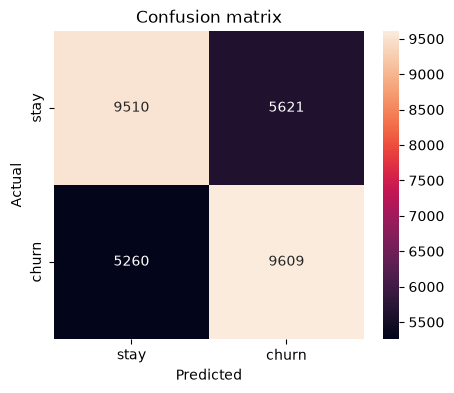

In [17]:
# Accuracy on the held-out test set
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

# Confusion matrix: rows = actual class, columns = predicted class
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['stay', 'churn'],
            yticklabels=['stay', 'churn'])
plt.title('Confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Questions to think about:**
- A baseline that always predicts the majority class would score around 0.5 here. Does your accuracy meaningfully beat that? If not, the model isn't adding evidence yet.
- Accuracy treats false positives and false negatives equally. Are they really equally costly for *your* proposal — flagging a stayer as a churner (wasted retention spend) versus missing a real churner (lost revenue)?
- What other metrics could you compute — AUC, precision, recall, F1? When would each be more informative than accuracy?
- If your accuracy looks suspiciously high, could a feature be leaking the target?

### 7.1 Feature importance

XGBoost reports several importance measures. Two simple ones: `weight` (how often a feature is used in any tree) and `gain` (how much it improves the model when used). For "which signals matter", `gain` is the more meaningful — a feature can be used often but contribute little, or rarely but decisively.

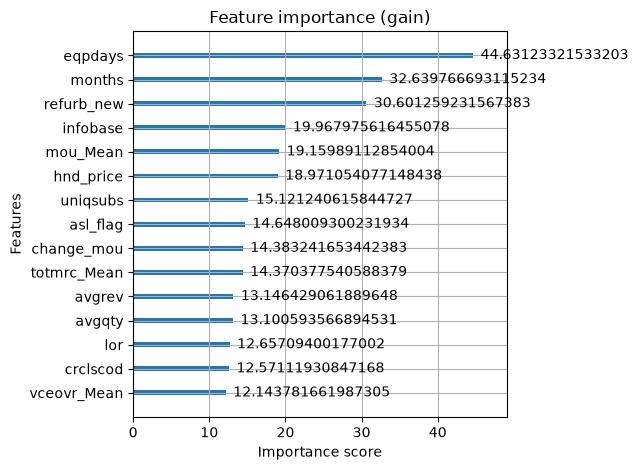

In [18]:
plot_importance(model, max_num_features=15, importance_type='gain')
plt.title('Feature importance (gain)')
plt.tight_layout()
plt.show()

**Questions to think about:**
- Pick the top 3–5 features. For each, can the business actually *change* it? Equipment age or customer-care call volume can be acted on; tenure and demographics cannot. Importance + intervenability is what produces a lever your proposal can pull.
- *Why* might each feature plausibly drive your target? Importance tells you the model uses a feature, not why — and a story a CFO can probe is what your proposal will be judged on.
- If you removed the top feature and retrained, does the next-most-important feature tell the same story, or does the ranking reshuffle? That tells you whether you have one robust signal or several correlated proxies for the same underlying driver.

### 7.2 Added — Calibration, gains, and revenue-at-risk capture

AUC tells us the ranking is informative. The proposal needs three more things:

1. **Calibration** — the probability is multiplied by dollars, so it must be close to the observed churn rate, not merely rank well. We report the expected calibration error (ECE) on out-of-fold predictions and a cross-fitted isotonic check.
2. **Gains** — how many churners and how many dollars of annual revenue at risk are captured as we expand the target list.
3. **A dollar-weighted comparison** — ranking by churn probability alone versus ranking by expected annual revenue at risk (`p × monthly revenue × 12`). The second is the deployment score.


,model,auc,auc_fold_std,pr_auc,log_loss,brier,ece_raw,ece_isotonic,top10_churn_p,top10_lift_p,top10_avg_bill_p,top10_rar_capture_p,top10_churn_value,top10_avg_bill_value,top10_rar_capture_value,top10_expected_rar_value
0,XGBoost (full),0.706,0.003,0.696,0.623,0.217,0.009,0.001,0.814,1.641,52.939,0.147,0.599,146.790,0.291,1.011103e+07
1,LightGBM (full),0.705,0.003,0.695,0.623,0.217,0.003,0.002,0.816,1.647,52.813,0.147,0.600,146.537,0.291,1.014084e+07
2,LightGBM (fair),0.703,0.004,0.694,0.625,0.218,0.002,0.001,0.815,1.645,52.520,0.146,0.601,146.648,0.292,1.014345e+07
3,Logistic,0.636,0.002,0.615,0.666,0.236,0.009,0.001,0.696,1.403,65.316,0.151,0.557,148.465,0.279,9.944681e+06


Deployed model: LightGBM (fair)
OOF AUC: 0.7029; PR-AUC: 0.6938; ECE: 0.0020

Value-ranked top decile: churn 60.1%, avg bill $146.65, RaR capture 29.2%
Probability-only top decile: churn 81.5%, avg bill $52.52, RaR capture 14.6%

Base economics: margin recovered $0.95M, program cost $0.30M, net $0.65M
Break-even relative churn reduction: 4.7% (2.8 pp)


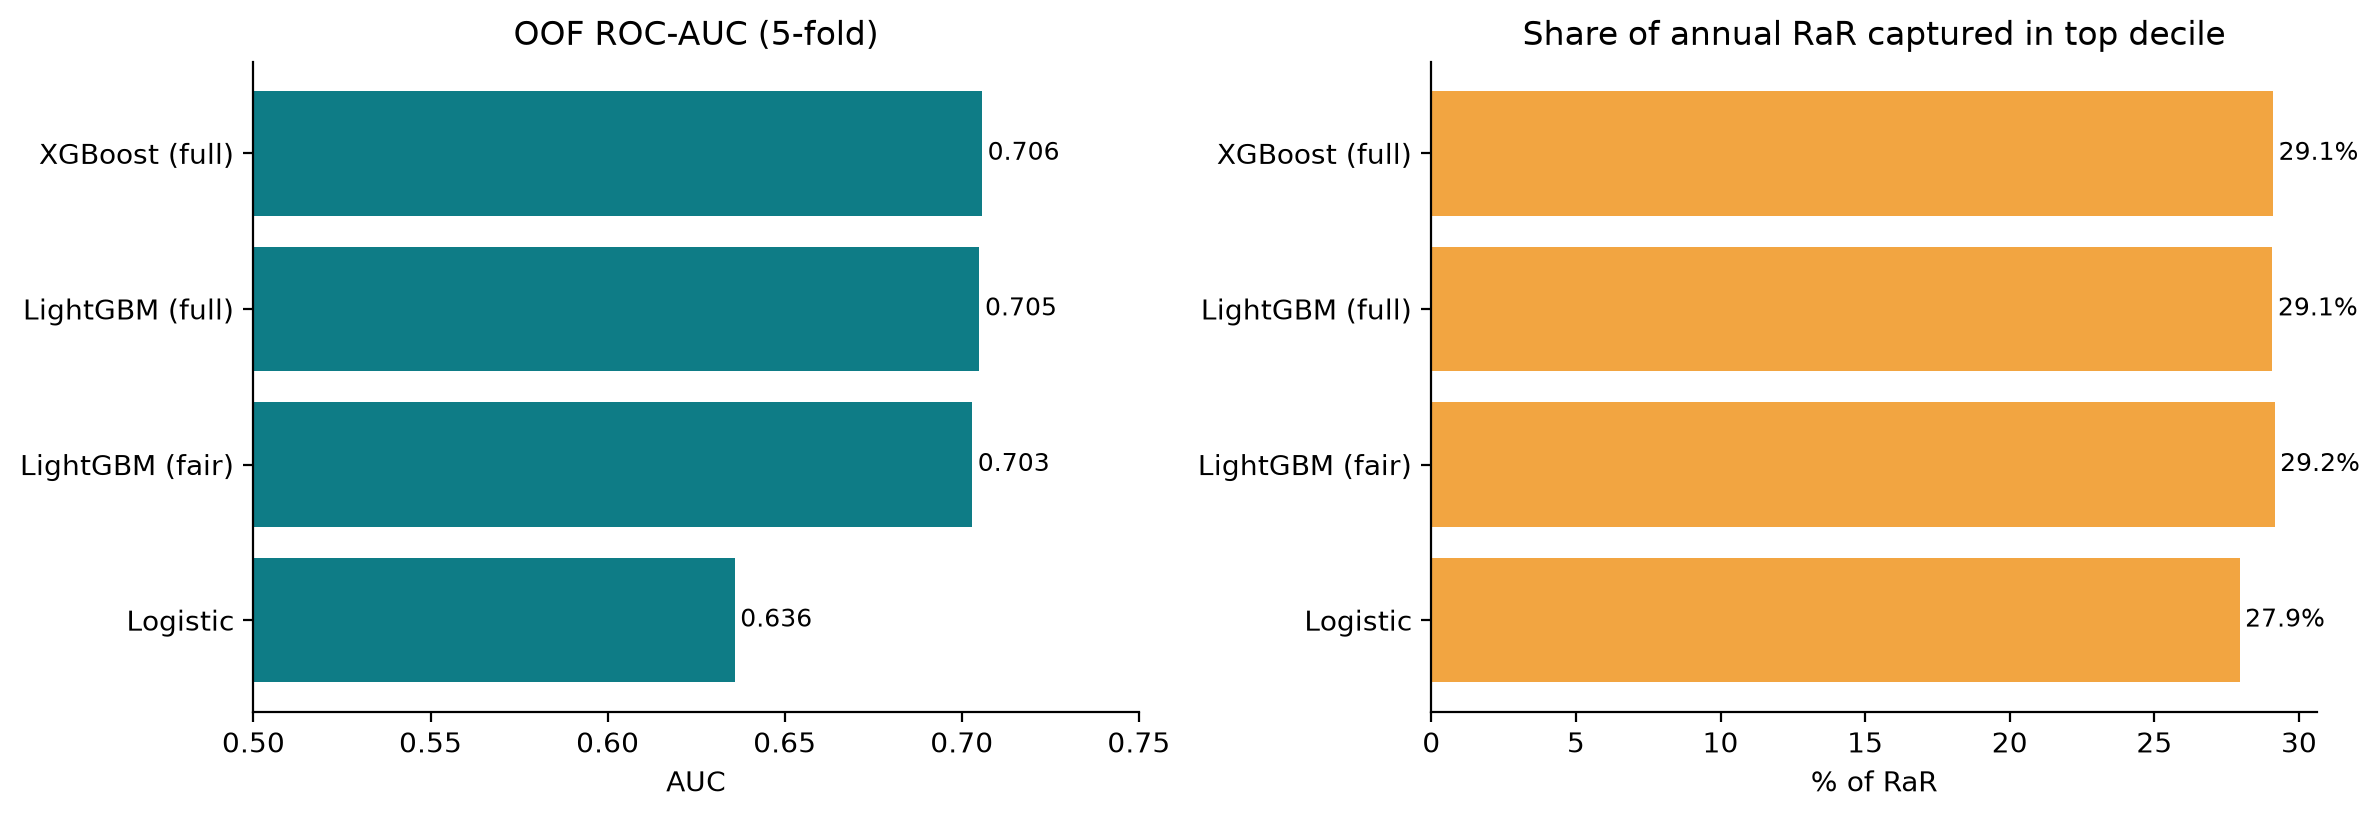

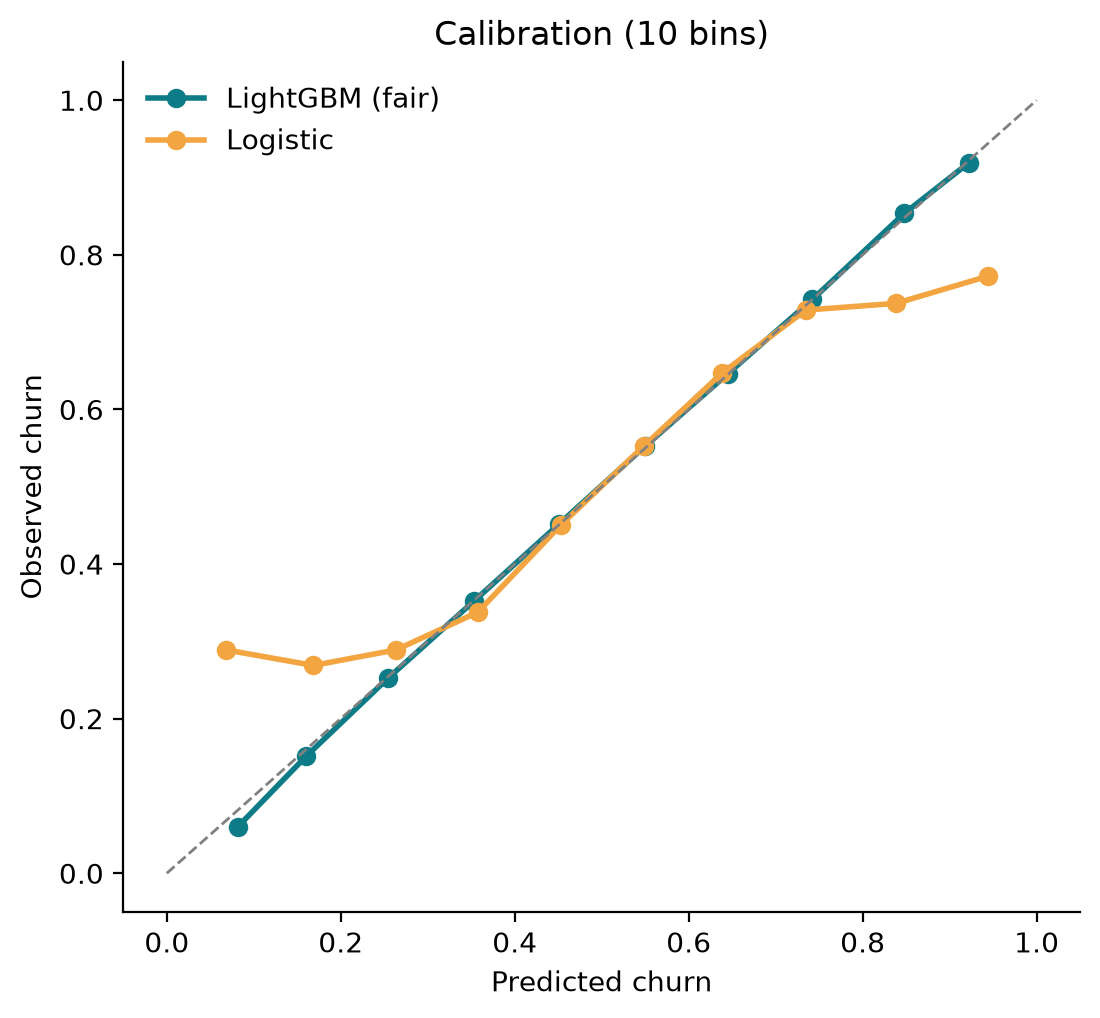

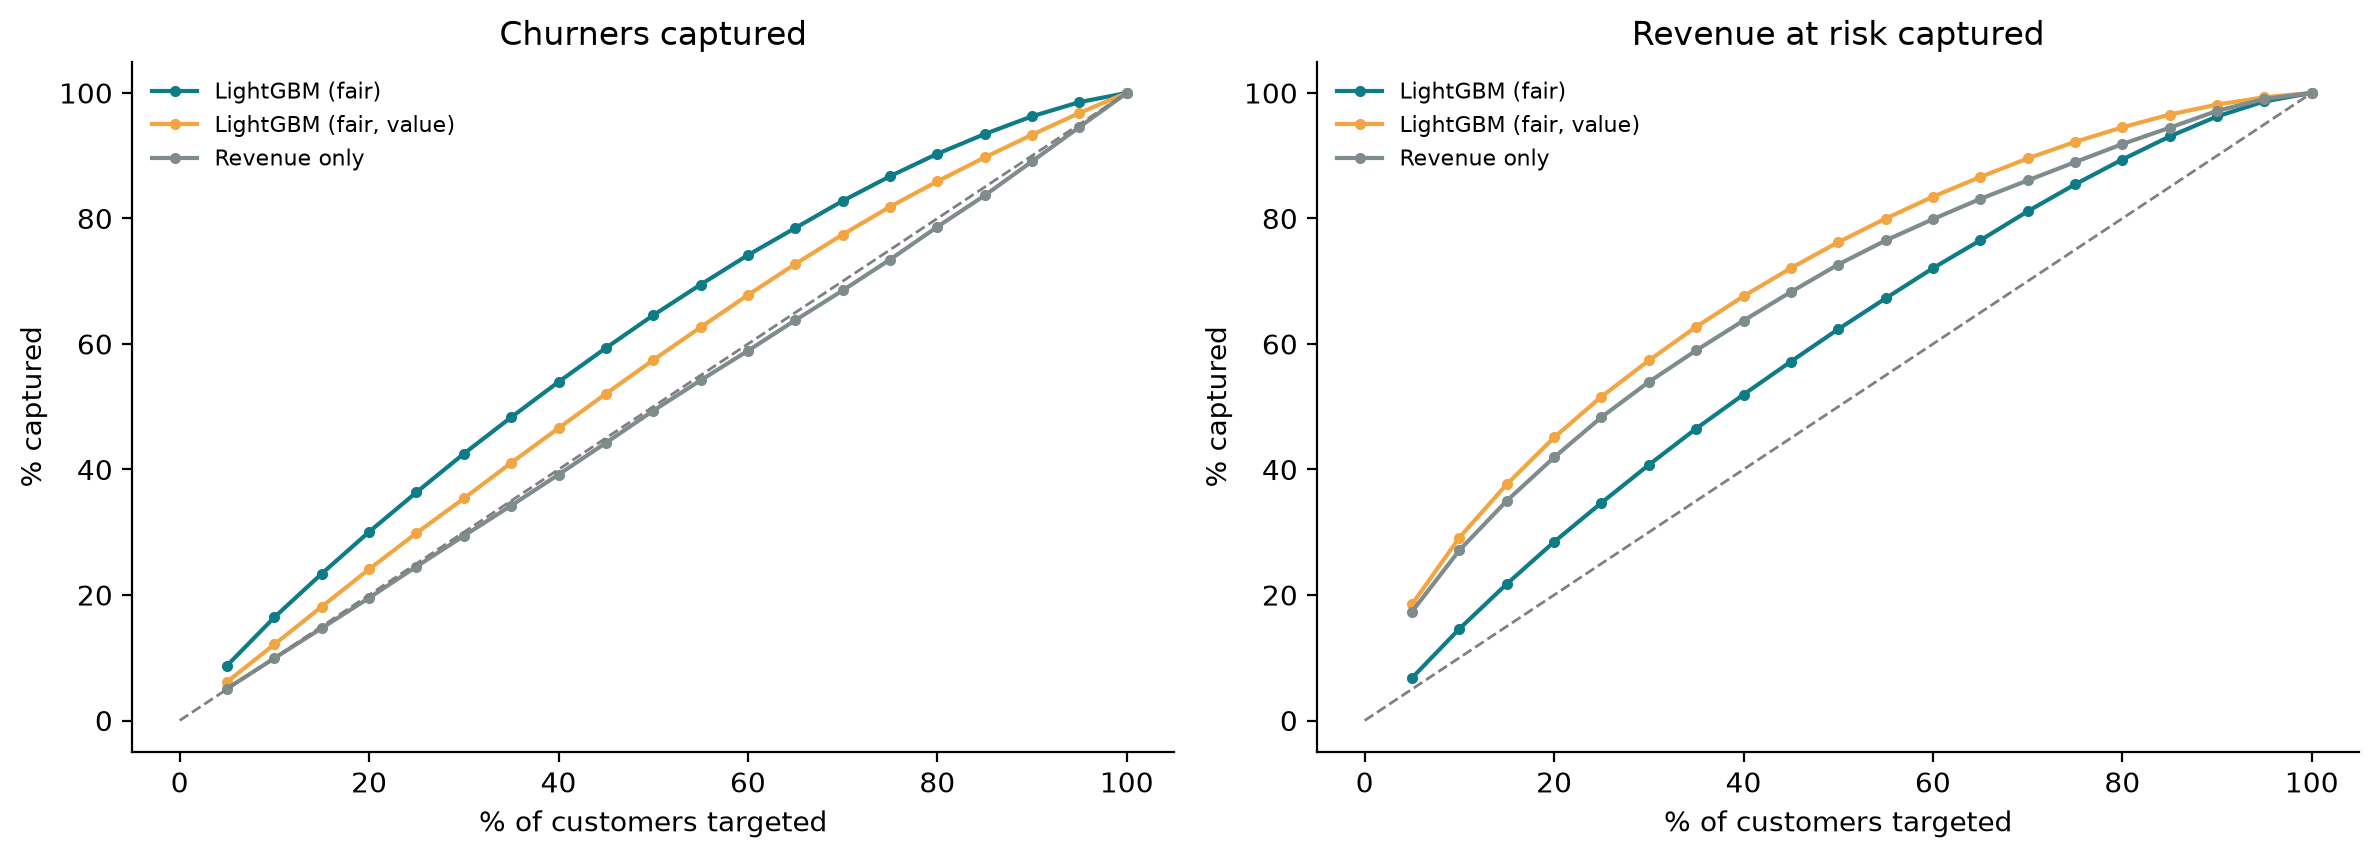

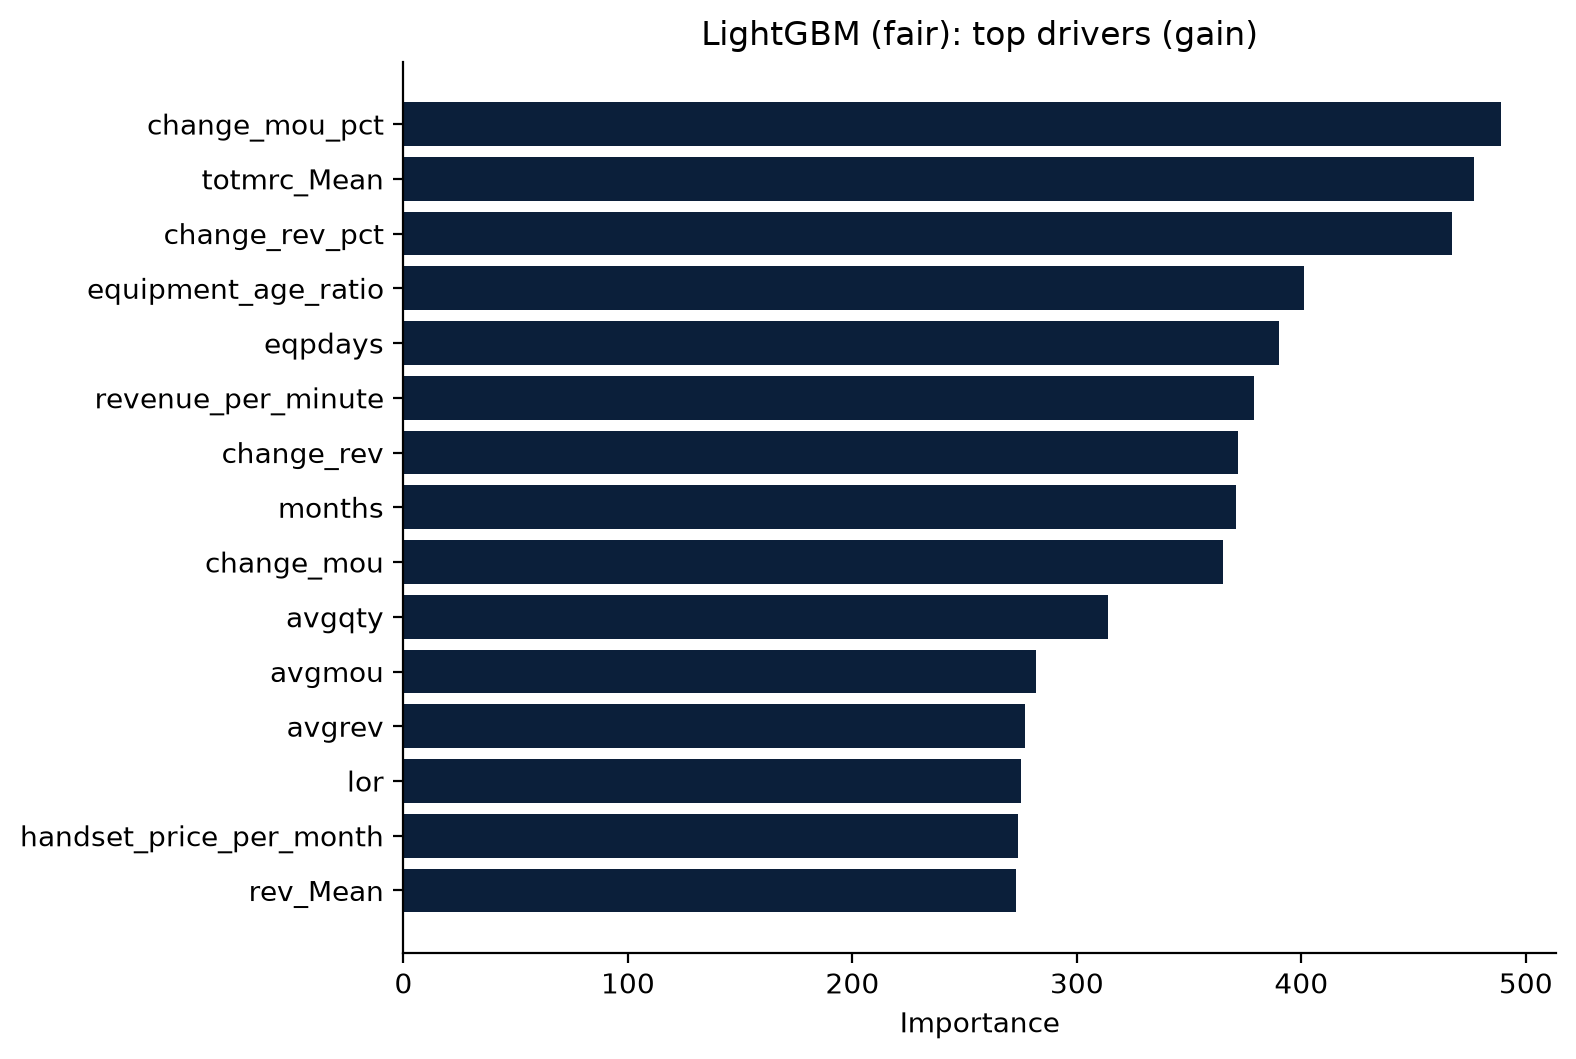

In [19]:
import json
from IPython.display import Image

out = OUT_DIR
metrics = json.loads((out / "metrics_models.json").read_text())
display(pd.DataFrame(metrics["model_comparison"]).round(3))

print(f"Deployed model: {metrics['deployed_model']}")
print(f"OOF AUC: {metrics['deployed_auc']:.4f}; PR-AUC: {metrics['deployed_pr_auc']:.4f}; ECE: {metrics['deployed_ece_raw']:.4f}")

value_top = metrics["top10_value_ranked"]
prob_top = metrics["top10_probability_only"]
print(f"\nValue-ranked top decile: churn {value_top['churn_rate']:.1%}, avg bill ${value_top['avg_monthly_rev']:.2f}, RaR capture {value_top['rar_capture']:.1%}")
print(f"Probability-only top decile: churn {prob_top['churn_rate']:.1%}, avg bill ${prob_top['avg_monthly_rev']:.2f}, RaR capture {prob_top['rar_capture']:.1%}")

econ = metrics["economics_value"]
print(f"\nBase economics: margin recovered ${econ['margin_recovered']/1e6:.2f}M, program cost ${econ['program_cost']/1e6:.2f}M, net ${econ['net']/1e6:.2f}M")
print(f"Break-even relative churn reduction: {econ['breakeven_relative_reduction']:.1%} ({econ['breakeven_absolute_pp']:.1f} pp)")

for name in ["fig_model_comparison.png", "fig_calibration.png", "fig_gains.png", "fig_feature_importance.png"]:
    display(Image(filename=str(FIG_DIR / name)))

**Read-out.** The fair LightGBM is statistically indistinguishable from the full-feature models (AUC ≈ 0.70) and is better calibrated than logistic regression. Ranking by expected revenue at risk roughly doubles the share of annual revenue at risk captured in the top decile compared with ranking by churn probability alone (≈29% versus ≈15%). That difference is the commercial case for a value-weighted score.


---

## 8.From Model to Proposal

The model gives a probability for each customer. By itself, that is not a proposal — it is one piece of evidence. The **proposal** is the recommendation: who to target, with what action, at what cost, for what expected return. Closing the gap is the assignment, and it is what separates a passing submission from a strong one.

A common failure mode is to present the model itself as the proposal ("we built a churn model with X% accuracy"). That is a technical report. The grading rubric wants a recommendation the model supports.

**Questions to think about:**
- Concretely, what does the business *do* with a customer flagged as high risk — a retention offer? A service call? A plan change? The answer determines what counts as a successful intervention.
- If you ranked customers by predicted score and targeted the top 10% (or 20%, or some other cutoff), what fraction of actual churners would you catch? What is the right cutoff given the cost of action versus inaction?
- What is the average revenue per customer, the cost of an intervention, and the probability that the intervention actually works? Without these numbers — sourced or assumed transparently — you cannot put a dollar figure on the recommendation.
- Multiplying through (customers targeted × success rate × value retained, minus campaign cost), what is the expected impact? This is what the grading rubric means by *quantified business impact*. Show your assumptions.
- What happens if the model is wrong? What does the proposal not capture — substitution, cannibalisation, seasonality?
- How will you visualize your findings in the slides? The charts in this notebook are intentionally minimal — just enough to make a point. Your proposal slides should use polished, well-labelled visualizations that each communicate one clear takeaway. A messy chart loses your audience faster than no chart at all, and "use multiple data visualizations" is an explicit grading criterion.

A proposal that ends at *"the model predicts churn well"* is incomplete. A proposal that ends at *"targeting the top 10% of customers by predicted score yields ~$X in retained revenue under these assumptions"* is a proposal.

### 8.1 Added — The Bill Certainty recommendation

**Target.** The top decile by expected annual revenue at risk (`p × monthly revenue × 12`) — 10,000 accounts in this sample, with a 60.1% observed churn rate, a $146.65 average monthly bill, and 29.2% of total annual revenue at risk.

**Offer.** A personalised, revenue-neutral unlimited plan priced close to the customer's recent average bill, plus a proactive bill-shock alert before the first cycle on the new plan. The customer gets a bill they can predict; Company A keeps a high-value account without discounting below the current revenue line.

**Pilot.** 90 days, randomised treatment/control, 10,000 targeted accounts. Success is a relative churn reduction above the 4.7% break-even (2.8 pp absolute), with a 15% relative reduction as the base case: ≈$0.95M contribution margin recovered against $0.30M program cost, ≈$0.65M net.

**Why not a blanket discount.** A 10% price cut needs roughly a 4.5 pp churn reduction to break even; Bill Certainty needs 2.8 pp because it protects the customers with the most dollars at risk and does not give away margin on customers who were staying.


---

## 9.Conclusion

This is the end of the tutorial. Two things to carry forward:

- **The assignment is a business proposal backed by data, not a data analysis dressed up as a proposal.** Use the model to support a clear recommendation, with quantified impact and stated assumptions.
- **Originality counts.** A proposal that segments customers in an unusual way, reframes the problem, or grounds itself in a market you know well will stand out.

Good luck.

---

### Notes
- XGBoost and LightGBM: the portable setup cell installs either package automatically if it is missing.
- The notebook uses no local paths. On a fresh Colab runtime it downloads the verified workspace bundle once, then runs end to end.

### 9.1 Added — Build guardrail check

This cell must print `GUARDRAIL CHECK: PASS` in the executed submission notebook.

On a fresh Colab runtime the original course folder is absent by design. The check then verifies the two working data copies against the recorded SHA-256 manifest and reports the reference originals as not present; no local files are required.

In [20]:
report = guardrails.verify_sources()
copies = guardrails.verify_copies()
summary = report["_summary"]
other_missing = [
    name for name in summary["originals_missing"]
    if name not in {"client_csv", "record_csv"}
]
print(f"Original course files present: {summary['originals_present']}/{summary['originals_recorded']}")
if other_missing:
    print("Reference originals not present in this environment:", ", ".join(other_missing))
print(f"Working data copies verified against SHA-256: {copies}")
print("GUARDRAIL CHECK: PASS")

Original course files present: 8/8
Working data copies verified against SHA-256: {'client_csv': True, 'record_csv': True}
GUARDRAIL CHECK: PASS
